# T1 Vision por computador Jose Quimi

Este archivo es para realizar los procesos paso a paso, posteriormente se arma un archivo main.py que ejecuta el codigo compelto por si solo

In [1]:
# imports
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [2]:
# imgs paths
img_path = os.path.join("..", "imgs")
# print(os.path.join(img_path, "img1.jpg"))
img1, img2, img3, img4 = [cv2.imread(os.path.join(img_path, f"img{i}.jpg")) for i in range(1, 5)]
N, M = img1.shape[:2] # eliminando el canal de color

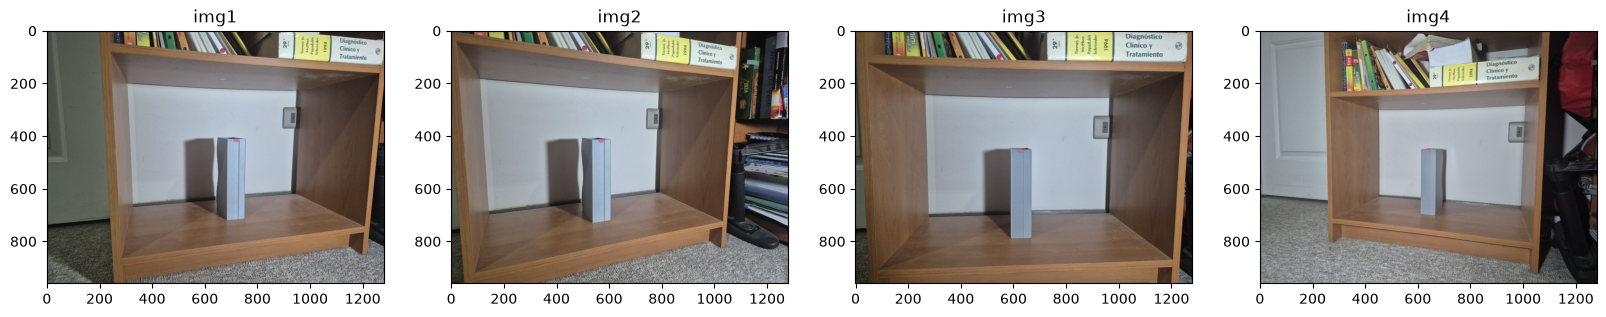

Shape = (960, 1280, 3)


In [3]:
# show imgs
fig, axs = plt.subplots(1, 4, figsize=(20, 10))
axs[0].imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB), cmap='gray')
axs[0].set_title('img1')

axs[1].imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB), cmap='gray')
axs[1].set_title('img2')

axs[2].imshow(cv2.cvtColor(img3, cv2.COLOR_BGR2RGB), cmap='gray')
axs[2].set_title('img3')

axs[3].imshow(cv2.cvtColor(img4, cv2.COLOR_BGR2RGB), cmap='gray')
axs[3].set_title('img4')
plt.show()
print(f"Shape = {img1.shape}")

Utilizando la imagen 3 como imagen explicativa, los puntos se disponen en el siguiente orden, siendo el punto 1 el punto de origen, ademas se indica el punto objetivo.

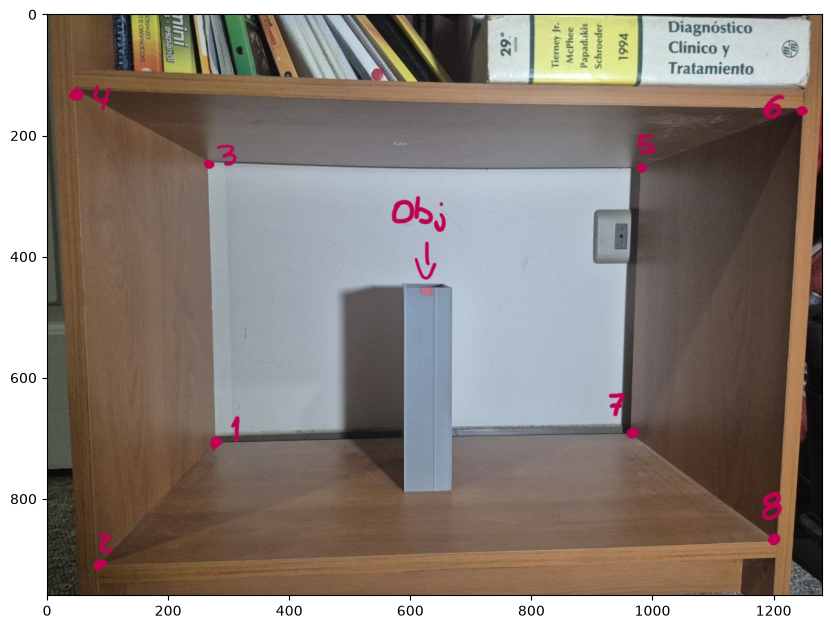

In [4]:
img_ej_path = os.path.join("..", "imgs/img_explicacion.jpg")
img_ej = cv2.imread(img_ej_path)
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(img_ej, cv2.COLOR_BGR2RGB), cmap='gray')
plt.show()

#### Obtener la matriz de calibracion de todas las imagenes

In [5]:
# definir M, los puntos reales con el punto 1 como el origen, todo en milimetros
M = np.array([
    [0.0,  0.0,   0.0,   0.0,   570.0, 570.0, 570.0, 570.0],
    [0.0,  294.0, 0.0,   294.0, 0.0,   294.0, 0.0,   294.0],
    [0.0,  0.0,   369.0, 369.0, 369.0, 369.0, 0.0,   0.0],
    [1.0,  1.0,   1.0,   1.0,   1.0,   1.0,   1.0,   1.0]
])
# lista de puntos
puntos_list_1 = []
puntos_list_2 = []
puntos_list_3 = []
puntos_list_4 = []

##### Funciones

In [6]:
# Funcion de calibracion de la camara
def calibracion(M,w):

  # Escribe código aquí
  n = M.shape[1]

  X_v = []

  for i in range(n):
    X, Y, Z = M[0, i], M[1, i], M[2, i]
    u, v = w[0, i], w[1, i]

    x_1 = np.array([X, Y, Z, 1, 0, 0, 0, 0, -u*X, -u*Y, -u*Z, -u])
    x_2 = np.array([0, 0, 0, 0, X, Y, Z, 1, -v*X, -v*Y, -v*Z, -v])

    # Apilar
    X_vi = np.vstack([x_1, x_2])

    if i == 0:
      X_v = X_vi
    else:
      X_v = np.vstack([X_v, X_vi])

  U, S, VT = np.linalg.svd(X_v)
  a = VT[-1,:]
  P = a.reshape(3, 4)

  return P
# Callback para mouse
def mouse_callback(event, x, y, flags, param):
    puntos_list, img = param
    if event == cv2.EVENT_LBUTTONDOWN:
        print(f"Clicked at: ({x}, {y})")
        puntos_list.append((x, y))
        
        cv2.circle(img, (x, y), 5, (0, 255, 0), -1)
        cv2.putText(img, f"{len(puntos_list)}", (x + 10, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
    elif event == cv2.EVENT_RBUTTONDOWN:
        if puntos_list:
            punto_removido = puntos_list.pop()
            print(f"Punto removido {punto_removido}")
        img[:] = img.copy()
        
        for index, (px, py) in enumerate(puntos_list):
            cv2.circle(img, (px, py), 5, (0, 255, 0), -1)
            cv2.putText(img, f"{index + 1}", (px + 10, py - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
            
# def obtener calibracion de imagen
def get_calibration(img, puntos_list):
    # levantar imagen y mostrarla en una ventana para obtener los puntos de las esquinas
    # una vez seleccionado los puntos apretar q para cerrar la ventana y guardar los puntos
    display_img = img.copy()
    flag = True
    cv2.namedWindow("Seleccionar puntos", cv2.WINDOW_NORMAL)
    # cv2.resizeWindow("Seleccionar puntos", img.shape[1], img.shape[0])
    cv2.setMouseCallback("Seleccionar puntos", mouse_callback, param=(puntos_list, display_img))

    while flag:
        cv2.imshow("Seleccionar puntos", display_img)
        key = cv2.waitKey(1) & 0xFF

        if key == ord('q'):
            flag = False
        elif key == ord('r'):
            puntos_list.clear()
            display_img = img.copy()
            print("Puntos reiniciados")
    cv2.destroyAllWindows()
    print(f"Puntos seleccionados: {puntos_list}")
    x, y = zip(*puntos_list)

    plt.figure(figsize=(10, 10))

    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), cmap='gray')
    plt.scatter(x, y, color='red', s=15)
    plt.show()
    print(f"Los puntos que representan la caja son: {puntos_list}")
    # obtener matriz de proyeccion P

    # Definir los vectores de m1
    x_p = np.array([p[0] for p in puntos_list])
    y_p = np.array([p[1] for p in puntos_list])
    print(f"x_p = {x_p}")
    print(f"y_p = {y_p}")

    m1 = np.vstack((x_p, y_p, np.ones(len(x_p))))
    print(m1)

    P = calibracion(M, m1)
    print(f"Matriz de proyeccion P = \n{P}")
    return (P, puntos_list)

def get_m1_mouse_callback(event, x, y, flags, param):
    state= param
    if event == cv2.EVENT_LBUTTONDOWN:
        print(f"Clicked at: ({x}, {y})")
        state['m1'] = np.array([x, y, 1])
        
        cv2.circle(state['display_img'], (x, y), 5, (0, 255, 0), -1)
        cv2.putText(state['display_img'], f"m1", (x + 10, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
    elif event == cv2.EVENT_RBUTTONDOWN:
        state['m1'] = None
        state['display_img'][:] = state['img_o'].copy()
        
def get_m1(img):
    """Esta funcion es el unico input del sistema, saca el punto rojo de la caja por medio del mouse y devuelve m1.
    Una vez seleccionado el punto, apretar q, para cerrar la ventana y guardar
    """
    flag = True
    display_img = img.copy()
    state = {'m1': None,
             'display_img': display_img,
             'img_o': img.copy()}
    cv2.namedWindow("Seleccionar punto rojo", cv2.WINDOW_NORMAL)
    # cv2.resizeWindow("Seleccionar punto rojo", display_img.shape[1], display_img.shape[0])
    cv2.setMouseCallback("Seleccionar punto rojo", get_m1_mouse_callback, param=state)
    while flag:
        cv2.imshow("Seleccionar punto rojo", display_img)
        key = cv2.waitKey(1) & 0xFF

        if key == ord('q'):
            flag = False
        elif key == ord('r'):
            state['m1'] = None
            state['display_img'] = state['img_o'].copy()
            print("Puntos reiniciados")
    cv2.destroyAllWindows()
    return state['m1']
    
    
    

Clicked at: (328, 669)
Clicked at: (284, 864)
Clicked at: (306, 199)
Clicked at: (243, 83)
Clicked at: (966, 228)
Clicked at: (1262, 162)
Clicked at: (946, 617)
Clicked at: (1208, 744)
Puntos seleccionados: [(328, 669), (284, 864), (306, 199), (243, 83), (966, 228), (1262, 162), (946, 617), (1208, 744)]


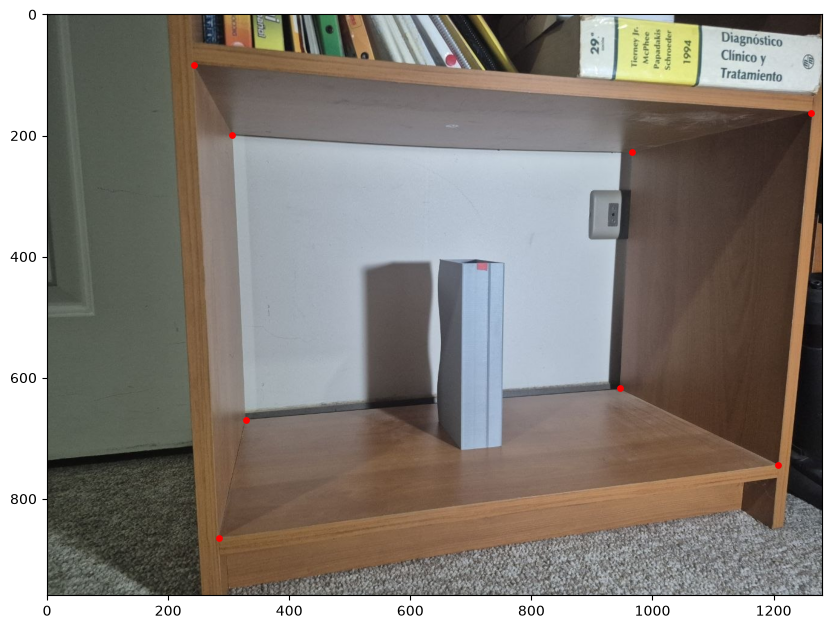

Los puntos que representan la caja son: [(328, 669), (284, 864), (306, 199), (243, 83), (966, 228), (1262, 162), (946, 617), (1208, 744)]
x_p = [ 328  284  306  243  966 1262  946 1208]
y_p = [669 864 199  83 228 162 617 744]
[[3.280e+02 2.840e+02 3.060e+02 2.430e+02 9.660e+02 1.262e+03 9.460e+02
  1.208e+03]
 [6.690e+02 8.640e+02 1.990e+02 8.300e+01 2.280e+02 1.620e+02 6.170e+02
  7.440e+02]
 [1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00
  1.000e+00]]
Matriz de proyeccion P = 
[[ 1.90495546e-03 -7.02684174e-04 -1.54173974e-04  4.40461349e-01]
 [ 1.74486754e-04 -6.32747454e-04 -1.76101539e-03  8.97766293e-01]
 [ 4.73323927e-07 -1.77211021e-06 -2.49364647e-07  1.34363914e-03]]
Clicked at: (145, 697)
Clicked at: (89, 919)
Clicked at: (110, 183)
Clicked at: (22, 45)
Clicked at: (805, 235)
Clicked at: (1071, 178)
Clicked at: (792, 613)
Clicked at: (1031, 724)
Puntos seleccionados: [(145, 697), (89, 919), (110, 183), (22, 45), (805, 235), (1071, 178), (792, 613), (1

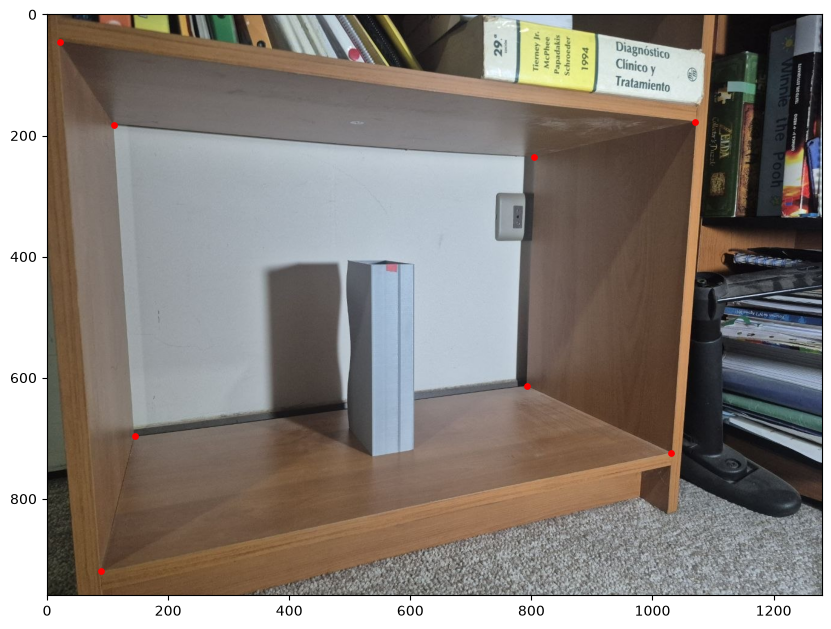

Los puntos que representan la caja son: [(145, 697), (89, 919), (110, 183), (22, 45), (805, 235), (1071, 178), (792, 613), (1031, 724)]
x_p = [ 145   89  110   22  805 1071  792 1031]
y_p = [697 919 183  45 235 178 613 724]
[[1.450e+02 8.900e+01 1.100e+02 2.200e+01 8.050e+02 1.071e+03 7.920e+02
  1.031e+03]
 [6.970e+02 9.190e+02 1.830e+02 4.500e+01 2.350e+02 1.780e+02 6.130e+02
  7.240e+02]
 [1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00
  1.000e+00]]
Matriz de proyeccion P = 
[[ 2.26927019e-03 -4.36415121e-04 -1.62449136e-04  2.03739488e-01]
 [ 3.20280415e-04 -6.89158839e-04 -2.01049096e-03  9.79019027e-01]
 [ 8.49199339e-07 -1.91627164e-06 -2.85715024e-07  1.40684900e-03]]
Clicked at: (278, 707)
Clicked at: (85, 909)
Clicked at: (265, 243)
Clicked at: (46, 124)
Clicked at: (979, 255)
Clicked at: (1248, 156)
Clicked at: (964, 691)
Clicked at: (1204, 871)
Puntos seleccionados: [(278, 707), (85, 909), (265, 243), (46, 124), (979, 255), (1248, 156), (964, 691), (1

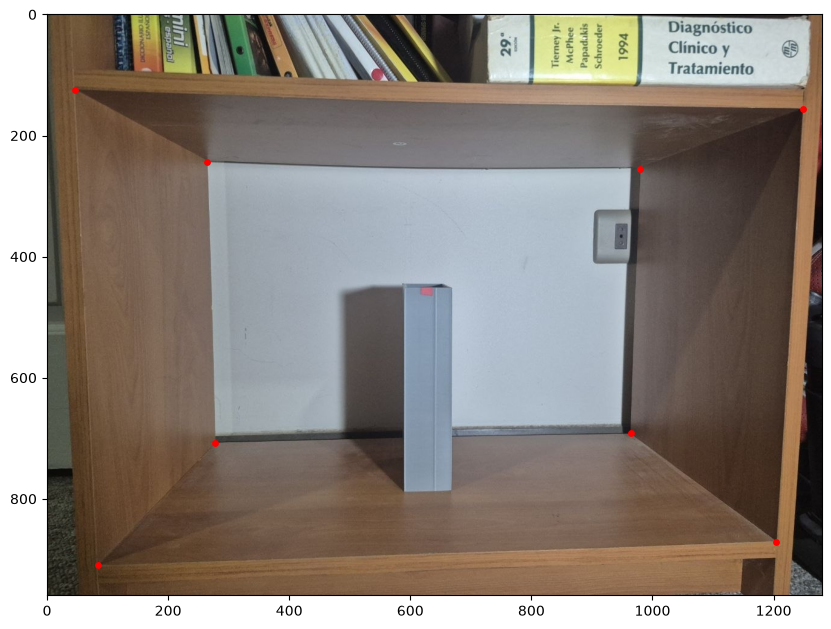

Los puntos que representan la caja son: [(278, 707), (85, 909), (265, 243), (46, 124), (979, 255), (1248, 156), (964, 691), (1204, 871)]
x_p = [ 278   85  265   46  979 1248  964 1204]
y_p = [707 909 243 124 255 156 691 871]
[[2.780e+02 8.500e+01 2.650e+02 4.600e+01 9.790e+02 1.248e+03 9.640e+02
  1.204e+03]
 [7.070e+02 9.090e+02 2.430e+02 1.240e+02 2.550e+02 1.560e+02 6.910e+02
  8.710e+02]
 [1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00
  1.000e+00]]
Matriz de proyeccion P = 
[[ 1.71108833e-03 -1.02267908e-03 -8.88822680e-05  3.66918186e-01]
 [ 6.09066509e-05 -7.27508603e-04 -1.69272489e-03  9.30248317e-01]
 [ 1.34570461e-07 -1.79961244e-06 -1.51926624e-07  1.31673976e-03]]
Clicked at: (453, 628)
Clicked at: (277, 713)
Clicked at: (449, 300)
Clicked at: (268, 252)
Clicked at: (1007, 284)
Clicked at: (1062, 216)
Clicked at: (990, 676)
Clicked at: (1035, 805)
Puntos seleccionados: [(453, 628), (277, 713), (449, 300), (268, 252), (1007, 284), (1062, 216), (990, 6

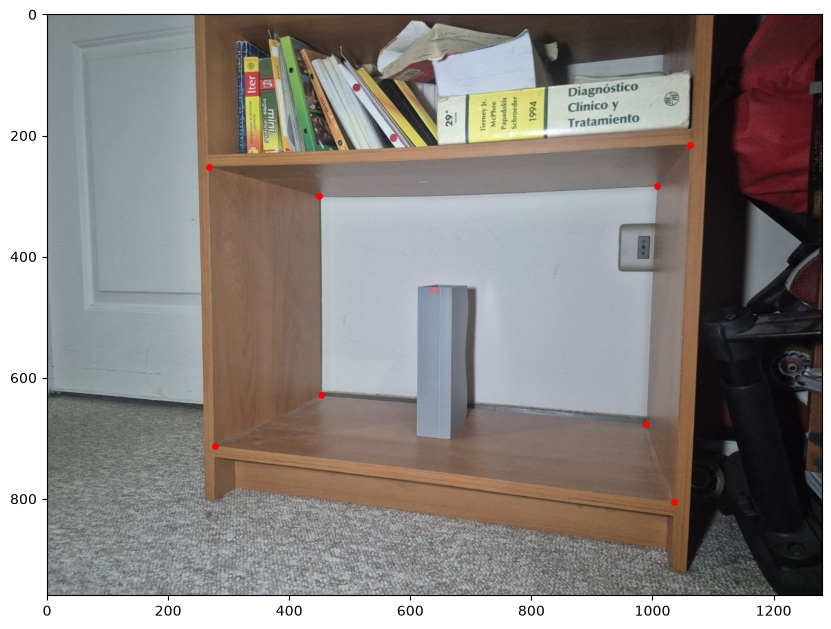

Los puntos que representan la caja son: [(453, 628), (277, 713), (449, 300), (268, 252), (1007, 284), (1062, 216), (990, 676), (1035, 805)]
x_p = [ 453  277  449  268 1007 1062  990 1035]
y_p = [628 713 300 252 284 216 676 805]
[[4.530e+02 2.770e+02 4.490e+02 2.680e+02 1.007e+03 1.062e+03 9.900e+02
  1.035e+03]
 [6.280e+02 7.130e+02 3.000e+02 2.520e+02 2.840e+02 2.160e+02 6.760e+02
  8.050e+02]
 [1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00
  1.000e+00]]
Matriz de proyeccion P = 
[[-8.66181198e-04  1.10850750e-03  5.39796199e-05 -5.83951246e-01]
 [ 1.34435012e-04  5.10458149e-04  1.18268765e-03 -8.11785450e-01]
 [ 3.55838815e-07  1.23105119e-06  1.01412492e-07 -1.29111548e-03]]


In [7]:
P1, puntos_list_1 = get_calibration(img1, puntos_list_1)
P2, puntos_list_2 = get_calibration(img2, puntos_list_2)
P3, puntos_list_3 = get_calibration(img3, puntos_list_3)
P4, puntos_list_4 = get_calibration(img4, puntos_list_4)

In [9]:
# mostrar los puntos para mantener el registro manualmente
print("Puntos seleccionados en las imagenes:")
print(f"Puntos primera imagen m1: {puntos_list_1}")
print(f"Puntos segunda imagen m2: {puntos_list_2}")
print(f"Puntos tercera imagen m3: {puntos_list_3}")
print(f"Puntos cuarta imagen m4: {puntos_list_4}")

print("Matrices de proyeccion")
print(f"Matriz de proyeccion P1 = \n{P1}")
print(f"Matriz de proyeccion P2 = \n{P2}")
print(f"Matriz de proyeccion P3 = \n{P3}")
print(f"Matriz de proyeccion P4 = \n{P4}")

P1 = np.array([
    [ 1.90495546e-03, -7.02684174e-04, -1.54173974e-04,  4.40461349e-01], 
    [ 1.74486754e-04, -6.32747454e-04, -1.76101539e-03,  8.97766293e-01], 
    [ 4.73323927e-07, -1.77211021e-06, -2.49364647e-07,  1.34363914e-03]
    ])
P2 = np.array([
    [ 2.26927019e-03, -4.36415121e-04, -1.62449136e-04,  2.03739488e-01],
    [ 3.20280415e-04, -6.89158839e-04, -2.01049096e-03,  9.79019027e-01],
    [ 8.49199339e-07, -1.91627164e-06, -2.85715024e-07,  1.40684900e-03]  
])
P3 = np.array([
    [ 1.71108833e-03, -1.02267908e-03, -8.88822680e-05,  3.66918186e-01],
    [ 6.09066509e-05, -7.27508603e-04, -1.69272489e-03,  9.30248317e-01],
    [ 1.34570461e-07, -1.79961244e-06, -1.51926624e-07,  1.31673976e-03]
])
P4 = np.array([
[-8.66181198e-04,  1.10850750e-03,  5.39796199e-05, -5.83951246e-01],
 [ 1.34435012e-04,  5.10458149e-04,  1.18268765e-03, -8.11785450e-01],
 [ 3.55838815e-07,  1.23105119e-06,  1.01412492e-07, -1.29111548e-03]
])
puntos_list_1 = [(328, 669), (284, 864), (306, 199), (243, 83), (966, 228), (1262, 162), (946, 617), (1208, 744)]
puntos_list_2 = [(145, 697), (89, 919), (110, 183), (22, 45), (805, 235), (1071, 178), (792, 613), (1031, 724)]
puntos_list_3 = [(278, 707), (85, 909), (265, 243), (46, 124), (979, 255), (1248, 156), (964, 691), (1204, 871)]
puntos_list_4 = [(453, 628), (277, 713), (449, 300), (268, 252), (1007, 284), (1062, 216), (990, 676), (1035, 805)]

Puntos seleccionados en las imagenes:
Puntos primera imagen m1: [(328, 669), (284, 864), (306, 199), (243, 83), (966, 228), (1262, 162), (946, 617), (1208, 744)]
Puntos segunda imagen m2: [(145, 697), (89, 919), (110, 183), (22, 45), (805, 235), (1071, 178), (792, 613), (1031, 724)]
Puntos tercera imagen m3: [(278, 707), (85, 909), (265, 243), (46, 124), (979, 255), (1248, 156), (964, 691), (1204, 871)]
Puntos cuarta imagen m4: [(453, 628), (277, 713), (449, 300), (268, 252), (1007, 284), (1062, 216), (990, 676), (1035, 805)]
Matrices de proyeccion
Matriz de proyeccion P1 = 
[[ 1.90495546e-03 -7.02684174e-04 -1.54173974e-04  4.40461349e-01]
 [ 1.74486754e-04 -6.32747454e-04 -1.76101539e-03  8.97766293e-01]
 [ 4.73323927e-07 -1.77211021e-06 -2.49364647e-07  1.34363914e-03]]
Matriz de proyeccion P2 = 
[[ 2.26927019e-03 -4.36415121e-04 -1.62449136e-04  2.03739488e-01]
 [ 3.20280415e-04 -6.89158839e-04 -2.01049096e-03  9.79019027e-01]
 [ 8.49199339e-07 -1.91627164e-06 -2.85715024e-07  1.40

##### Obtener m1 de la imagen 1

Clicked at: (718, 415)
El punto rojo m1 es: [[718]
 [415]
 [  1]]


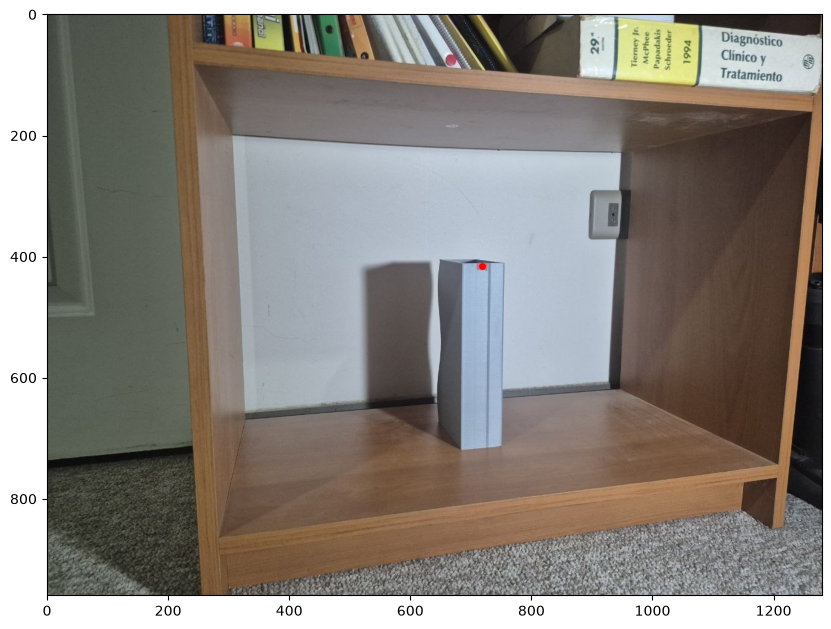

In [10]:
m1 = get_m1(img1)
m1 = np.array(m1).reshape(3, 1)
print(f"El punto rojo m1 es: {m1}")
# print(f"m1: {m1[0]}, {m1[1]}")
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB), cmap='gray')
plt.scatter(m1[0], m1[1], color='red', s=15)
plt.show()

#### Realizar homografia desde img 1 a img2

In [11]:
# Extraido de E02
def homography(X,H):
  N, M, C = X.shape
  Hinv  = np.linalg.inv(H)
  Xp    = np.zeros((N,M,C),np.uint8)

  m = np.ones((N*M,3))
  t = 0
  for i in range(N):
    for j in range(M):
      m[t,0:2] = [j,i]
      t = t+1

  mph = np.dot(Hinv,m.T)  # Transformation m to mp
  mp  = np.divide(mph[0:2,:],mph[2,:])
  mpf = np.trunc(mp).astype(int) #np.fix is deprecated

  ip = mpf[1,:]
  jp = mpf[0,:]
  
  ktj = np.logical_and(jp >= 0,  jp<M)
  kti = np.logical_and(ip >=0, ip < N)
  kt  = np.logical_and(kti, ktj)

  t = 0
  for i in range(N):
    for j in range(M):
      if kt[t]:
        Xp[i,j] = X[ip[t],jp[t]]
      t = t+1
  return Xp

def homography_matrix(m,mp):
  (x ,y ) = m
  (xp,yp) = mp
  n       = len(x)
  A       = np.zeros((2*n,9))
  for i in range(n):
    j = i*2
    A[j  ,:] = [x[i], y[i], 1,     0,     0, 0, -x[i]*xp[i], -y[i]*xp[i], -xp[i]]
    A[j+1,:] = [  0  ,   0  , 0, x[i], y[i], 1, -x[i]*yp[i], -y[i]*yp[i], -yp[i]]
  [U,S,V] = np.linalg.svd(A)
  h       = V[-1,:]
  H       = np.vstack([h[0:3], h[3:6], h[6:9]])
  return H

def homography_with_calibration(P1, P2):
  H = None
  # obtener submatrices de P1 y P2 usando descomposicion RQ Szeliski
  M1 = P1[:, :3] # como P1 y P2 son con el mismo centro optico, la traslacion (t) es 0, K es igual porque es la misma camara y centro optico es 0
  M2 = P2[:, :3] # como P1 y P2 son con el mismo centro optico, la traslacion (t) es 0, K es igual porque es la misma camara y centro optico es 0
  # solo es diferente la rotacion.
  M_intercambiado_1 = M1[::-1, ::-1]
  K_temp, R_temp = np.linalg.qr(M_intercambiado_1.T) #usando la qr de numpy
  
  M_intercambiado_2 = M2[::-1, ::-1]
  K_temp2, R_temp2 = np.linalg.qr(M_intercambiado_2.T) 
  #reconstruir K y R a partir de las submatrices obtenidas
  K_1 = R_temp.T[::-1, ::-1]
  R_r1 = K_temp.T[::-1, ::-1]
  K_2 = R_temp2.T[::-1, ::-1]
  R_r2 = K_temp2.T[::-1, ::-1]

  #correccion de signos
  T1 = np.diag(np.sign(np.diag(K_1)))
  K1 = K_1 @ T1
  R1 = T1 @ R_r1
  
  T2 = np.diag(np.sign(np.diag(K_2)))
  K2 = K_2 @ T2
  R2 = T2 @ R_r2
  
  #normalizacion homogenea
  K1 = K1 / K1[2, 2] # esto fuerza que el ultimo elemento sea 1
  K2 = K2 / K2[2, 2]
  
  # Rotacion relativa
  R = R2 @ R1.T
  
  # armar matriz de homografia
  H = K2 @ R @ np.linalg.inv(K1)
  
  return H
        

In [12]:
# obtener matriz de homografia
H = homography_with_calibration(P1, P2)
print(f"Matriz de homografia H = \n{H}")

Matriz de homografia H = 
[[ 1.09689684e+00  1.66046170e-02 -2.25373299e+02]
 [ 6.62174126e-02  9.99290634e-01 -4.27562092e+01]
 [ 1.71904502e-04  2.72257465e-06  8.77116923e-01]]


## Obtener m2 a partir de la homografia

Matriz de homografia H = 
[[ 1.09689684e+00  1.66046170e-02 -2.25373299e+02]
 [ 6.62174126e-02  9.99290634e-01 -4.27562092e+01]
 [ 1.71904502e-04  2.72257465e-06  8.77116923e-01]]
m1: [[718]
 [415]
 [  1]]
El punto rojo m2 es: [[568.13835811]
 [418.79235418]
 [  1.        ]]


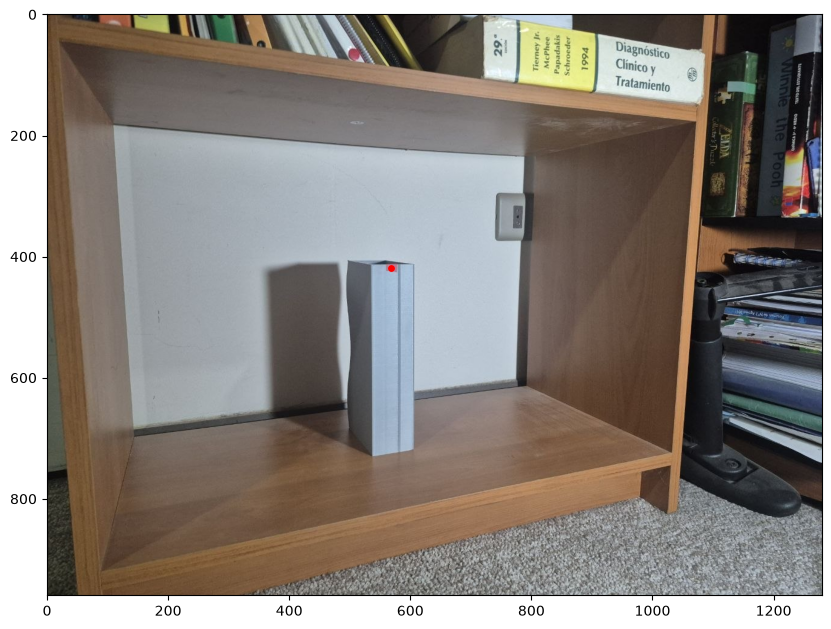

In [13]:
m2 = H @ m1
m2 = m2 / m2[2]  # Normalizar el punto m2 para que la tercera coordenada sea 1
print(f"Matriz de homografia H = \n{H}")
print(f"m1: {m1}")
print(f"El punto rojo m2 es: {m2}")
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB), cmap='gray')
plt.scatter(m2[0], m2[1], color='red', s=15)
plt.show()

# Obtener m3 a partir de m2

Utilizando las matrices de proyeccion para obtener la matriz fundamental

In [21]:
# siendo P2 y P3 las matrices de proyeccion de la imagen 2 y 3 respectivamente
#inspirado en solucion de E4
def get_m3_from_m2(m2, P2, P3, img3, graph=False):
    # obtener el nullspace desde P2, para armar C2
    U_P2, S_P2, Vt_P2 = np.linalg.svd(P2)
    #identificar los numeros que esten debajo de la tolerancia
    null_mask = np.zeros(P2.shape[1], dtype=bool)
    null_mask[len(S_P2): ] = True
    null_mask[: len(S_P2)] = S_P2 < 1e-13
    
    C2 = Vt_P2.T[:, null_mask]
    print(f"m2 = {m2}")
    
    # proyectar C2 en la imagen 3 para sacar Bc2 antisimetrica
    u = P3 @ C2
    u_anti = np.array([
    [0, -u[2][0], u[1][0]],
    [u[2][0], 0, -u[0][0]],
    [-u[1][0], u[0][0], 0]
    ])
    print(f"u_anti = {u_anti}")
    
    # armar la matriz pseudoinversa
    pseudo_inv = P2.T @ np.linalg.inv(P2 @ P2.T) 
    print(f"pseudo_inv = {pseudo_inv}")
    
    # armar matriz fundamental F
    F = u_anti @ P3 @ pseudo_inv
    
    # obtener la recta epipolar l3
    l3 = F @ m2
    l3 = l3 / l3[2] 
    print(f"l3 = {l3}")
    if graph:
        x_ep, y_ep = graficar_linea_epipolar(img3, l3, m2)
    else:
        x_ep = np.linspace(m2[0]-100, m2[0] + 500, 100)
        y_ep = ((-l3[0, 0]*x_ep - l3[2, 0]) / l3[1, 0])
        
    # por procesamiento de imagen encontrar el elemento rojo a lo largo de la imagen 3, y devolverlo como m3
    m3 = find_red_point_in_epipolar_line(img3, x_ep, y_ep)
    return m3

def graficar_linea_epipolar(img, l, m):
    img_display = img.copy()
    a = l[0, 0]
    b = l[1, 0]
    c = l[2, 0]
    x_m, y_m = m[0], m[1]
    plt.figure(figsize=(10, 10))
    plt.imshow(cv2.cvtColor(img_display, cv2.COLOR_BGR2RGB))

    
    x_ep = np.linspace(x_m-100, x_m + 500, 100)
    y_ep = ((-a*x_ep - c) / b)
    # print(f"y_ep = {len(y_ep)}")
    plt.plot(x_ep, y_ep, 'g-', linewidth=2)
    plt.grid(False)
    plt.show()
    return x_ep, y_ep
    
def find_red_point_in_epipolar_line(img, x_ep, y_ep):
    #hacer un algoritmo que busque el primer pixel rojo y el ultimo a lo largo de toda la linea epipolar y devolver el medio
    img = img.copy()
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    red_low_1 = np.array([0, 100, 50])
    red_high_1 = np.array([10, 255, 255])
    red_low_2 = np.array([170, 100, 50])
    red_high_2 = np.array([180, 255, 255])
    # print(f"x_ep = {x_ep[1]}")
    # print(f"y_ep = {y_ep}")

    pixeles_rojos = []
    h, w = img.shape[:2]
    for x, y in zip(x_ep, y_ep):
        # print(f"x = {x[0]}, y = {y[0]}")
        x = round(x[0])
        y = round(y[0])
        pixel = hsv[y, x]
        
        if (np.all(red_low_1 <= pixel) and np.all(pixel <= red_high_1)) or (np.all(red_low_2 <= pixel) and np.all(pixel <= red_high_2)):
            pixeles_rojos.append((x, y))
            
    first_x, first_y = pixeles_rojos[0]
    last_x, last_y = pixeles_rojos[-1]
    mid_x = (first_x + last_x) // 2
    mid_y = (first_y + last_y) // 2
    return np.array([mid_x, mid_y, 1]).reshape(3, 1)
    
    

m2 = [[568.13835811]
 [418.79235418]
 [  1.        ]]
u_anti = [[ 0.00000000e+00 -2.66010732e-08  1.98224313e-05]
 [ 2.66010732e-08  0.00000000e+00 -3.66492632e-04]
 [-1.98224313e-05  3.66492632e-04  0.00000000e+00]]
pseudo_inv = [[ 4.60407861e+02 -1.51296713e+01 -5.61475609e+04]
 [-1.73459409e+01  1.68757394e+02 -1.14926242e+05]
 [-7.49571498e+01 -4.89695554e+02  3.51631610e+05]
 [-3.16760342e-01  1.39545707e-01  6.59571146e+02]]
l3 = [[ 4.90300664e-05]
 [-2.24847450e-03]
 [ 1.00000000e+00]]


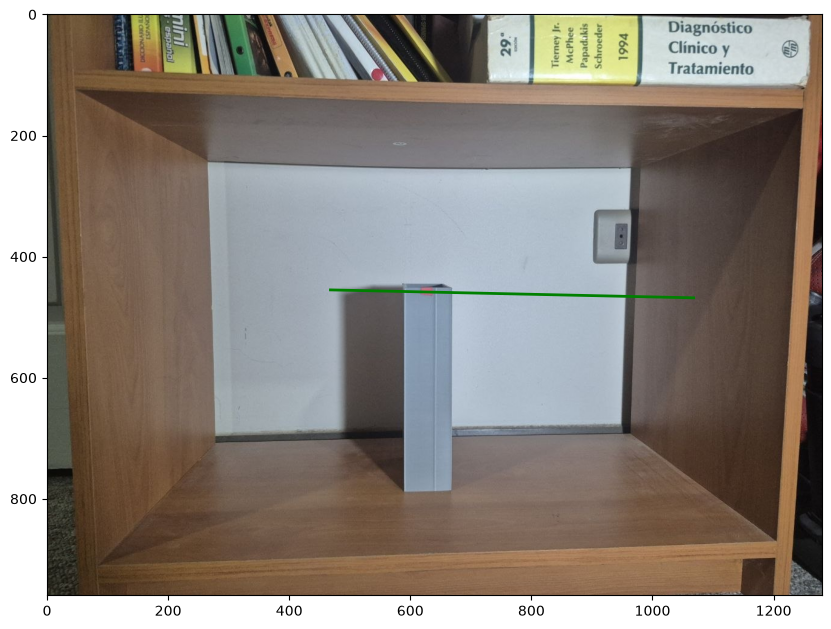

El punto rojo m3 es: [[626]
 [458]
 [  1]]


In [22]:
m3 = get_m3_from_m2(m2, P2, P3, img3, graph=True)
print(f"El punto rojo m3 es: {m3}")

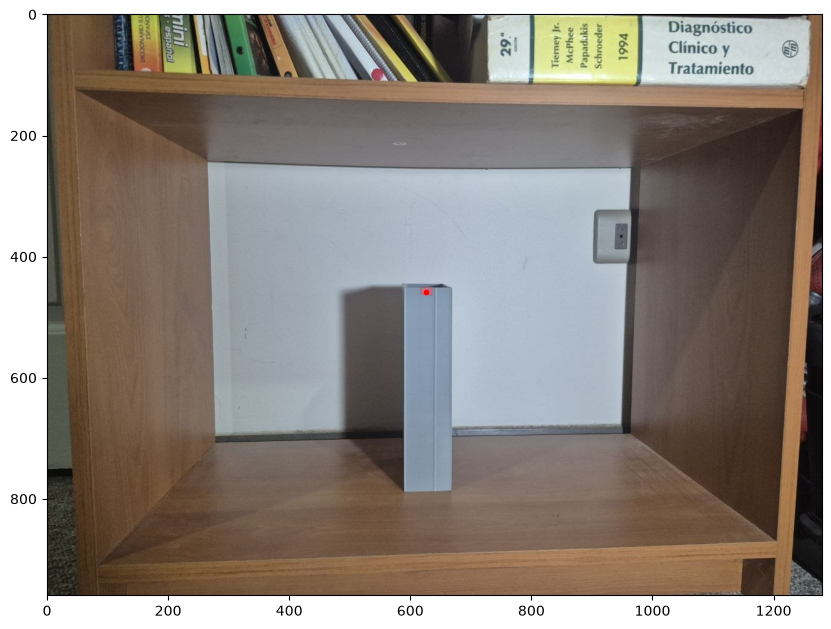

In [23]:
# graficar el punto m3 en la imagen 3
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(img3, cv2.COLOR_BGR2RGB))
plt.plot(m3[0], m3[1], 'ro', markersize=3)
plt.show()

## Obtener m4 a partir de m1, m2 y m3

Obtener la matriz fundamental entre 2 y 4 y 3 y 4, de esa manera sacar 2 lineas epipolares e intersectarlas

In [32]:
# funciones

def get_F(P1, P2):
    # obtener el nullspace desde P1, para armar C1
    U, S, Vt = np.linalg.svd(P1)
    #identificar los numeros que esten debajo de la tolerancia
    null_mask = np.zeros(P2.shape[1], dtype=bool)
    null_mask[len(S): ] = True
    null_mask[: len(S)] = S < 1e-13
    
    C1 = Vt.T[:, null_mask]
    
    # proyectar C1 en la imagen 2 para sacar Bc1 antisimetrica
    u = P2 @ C1
    u_anti = np.array([
    [0, -u[2][0], u[1][0]],
    [u[2][0], 0, -u[0][0]],
    [-u[1][0], u[0][0], 0]
    ])
    # print(f"u_anti = {u_anti}")
    
    # armar la matriz pseudoinversa
    pseudo_inv = P1.T @ np.linalg.inv(P1 @ P1.T) 
    # print(f"pseudo_inv = {pseudo_inv}")
    
    # armar matriz fundamental F
    F = u_anti @ P2 @ pseudo_inv
    return F
    
def get_m4_from_m3(m2, m3, P2 ,P3, P4, img4, graph=False):
    F24 = get_F(P2, P4)
    F34 = get_F(P3, P4)
    
    # optener rectas epipolares
    l2 = F24 @ m2
    l2 = l2 / l2[2]
    l3 = F34 @ m3
    l3 = l3 / l3[2]
    print(f"l2 = {l2}")
    print(f"l3 = {l3}")
    # obtener la interseccion
    m4 = np.cross(l2.flatten(), l3.flatten())
    m4 = m4 / m4[2]
    print(f"El punto rojo m4 es: {m4}")
    if graph:
        x_ep2, y_ep2 = graficar_linea_epipolar(img4, l2, m2)
        x_ep3, y_ep3 = graficar_linea_epipolar(img4, l3, m3)
        plt.figure(figsize=(10, 10))
        plt.imshow(cv2.cvtColor(img4, cv2.COLOR_BGR2RGB))
        plt.plot(m4[0], m4[1], 'ro', markersize=5)
        plt.show()


l2 = [[ 1.19376663e-04]
 [-2.36588199e-03]
 [ 1.00000000e+00]]
l3 = [[ 1.23053801e-04]
 [-2.37255779e-03]
 [ 1.00000000e+00]]
El punto rojo m4 es: [844.74537631 465.29915266   1.        ]


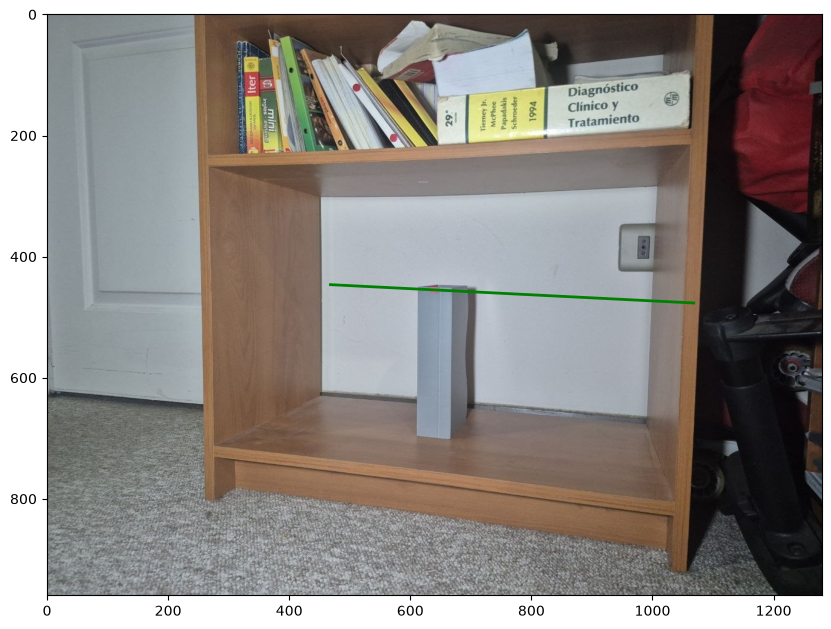

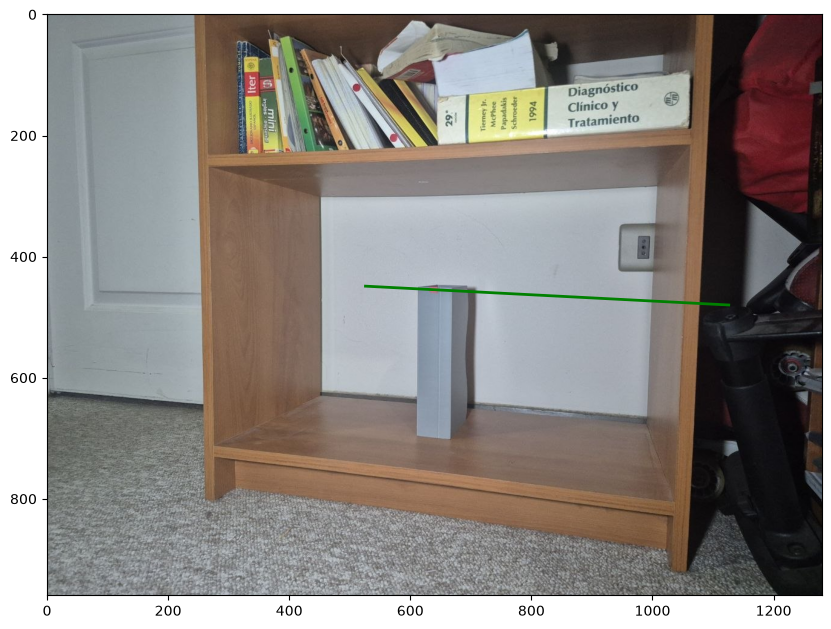

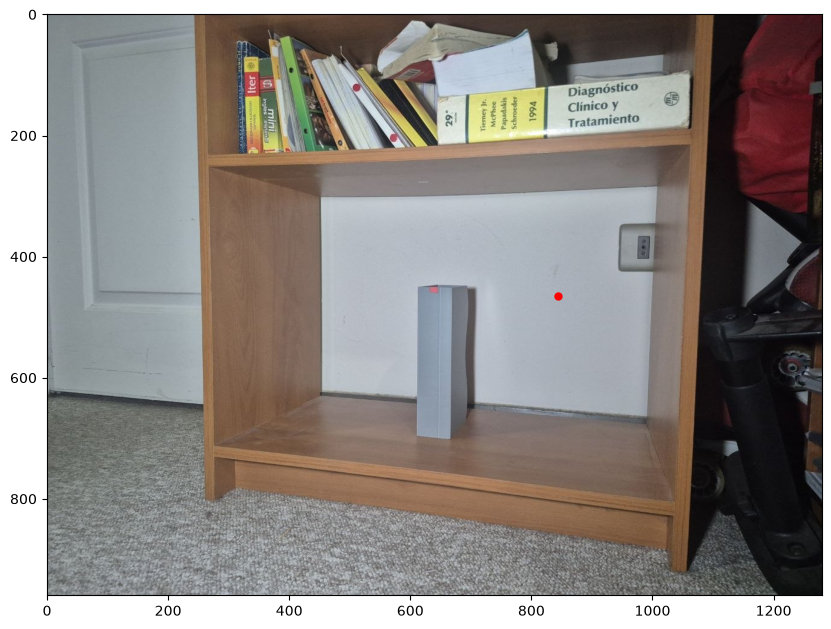

In [33]:
get_m4_from_m3(m2, m3, P2, P3, P4, img4, graph=True)